<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/Day07_Cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 7 — Auto MPG Feature Engineering and Model Comparison **Dataset:** Auto MPG, official train/test split
**Models on the bench:** Linear Regression, KNN Regressor, Decision Tree Regressor **The plan for today:**
1. Pull a clean `brand` out of the car `name` and invent a few physical features, without letting test data leak in.
2. Check skewness, and see whether a log-transformed target tidies up the residuals.
3. Race 3 algorithms on raw features versus engineered features, with the same 5 folds.
4. Draw bias-variance curves to see where each model starts to overfit.
5. Touch the test set once, at the end.
6. Prove with an experiment that KNN really does care about scaling.
7. Stretch goals: Ridge, Lasso, polynomial interactions, and a brand-effect plot. > Note to self: a tidy notebook is not the same as a correct one. Every number below has to come from running the cells, and nothing gets typed in by hand.


In [1]:
# Toolbox, one seed for everything, and a small helper I'll reuse for scoring
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)


def compute_regression_metrics(model, X_eval, y_eval, name='Model'):
    """RMSE, MAE and R2 for an already-fitted estimator."""
    preds = model.predict(X_eval)
    return {
        'Model': name,
        'RMSE': float(np.sqrt(mean_squared_error(y_eval, preds))),
        'MAE': float(mean_absolute_error(y_eval, preds)),
        'R2': float(r2_score(y_eval, preds)),
    }


## Step 1 — Feature engineering without cheating The `name` column looks like `chevrolet chevelle malibu`, so the first word is the brand. The catch is that the data is messy: `chevy`, `chevroelt` and `chevrolet` are the same company, and the same goes for `vw`, `vokswagen` and `volkswagen`. I fix those with a small lookup dictionary. Then comes the rule that matters most: **which brands count as "frequent" is decided from the training set only.** Anything with fewer than 5 training cars becomes `other`. If I counted brands using the test set too, test information would leak into my features. I'm also adding three physical features:
- `car_age` = 83 minus `model_year`, so a younger car gets a smaller number.
- `power_to_weight` = horsepower / weight.
- `disp_per_cyl` = displacement / cylinders, a rough measure of how big each cylinder is.


In [2]:
# Load separate train/test files when available. If only one CSV is supplied,
# split it once so the same rows are not used for both training and testing.
train_path_candidates = [
    "02_Dataset/auto_mpg_train - auto_mpg_train.csv",
    "auto_mpg_train - auto_mpg_train.csv",
]
test_path_candidates = [
    "auto_mpg_test - auto_mpg_test.csv",
    "auto_mpg_test - auto_mpg_test.csv",
]
full_path_candidates = ["02_Dataset/auto_mpg.csv", "auto_mpg.csv"]

train_path = next((p for p in train_path_candidates if os.path.exists(p)), None)
test_path = next((p for p in test_path_candidates if os.path.exists(p)), None)
full_path = next((p for p in full_path_candidates if os.path.exists(p)), None)

if train_path and test_path:
    train_raw = pd.read_csv(train_path)
    test_raw = pd.read_csv(test_path)
    print(f"Loaded separate files: {train_path} and {test_path}")
elif full_path:
    full_df = pd.read_csv(full_path)
    train_raw, test_raw = train_test_split(
        full_df, test_size=0.20, random_state=SEED
    )
    print(f"Loaded {full_path} and made an 80/20 train-test split.")
else:
    available_path = next(
        (p for p in ["auto_mpg_test.csv", "02_Dataset/auto_mpg_test.csv"]
         if os.path.exists(p)),
        None
    )
    if available_path is None:
        raise FileNotFoundError(
            "Auto MPG data not found. Place auto_mpg_train.csv and "
            "auto_mpg_test.csv in the notebook folder, or provide auto_mpg.csv."
        )
    full_df = pd.read_csv(available_path)
    train_raw, test_raw = train_test_split(
        full_df, test_size=0.20, random_state=SEED
    )
    print(
        f"Only {available_path} was found; treating it as the available dataset "
        "and splitting it 80/20. For an official holdout evaluation, use the "
        "original separate training and test files."
    )

required_columns = {
    "mpg", "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin", "name"
}
for label, frame in [("training", train_raw), ("test", test_raw)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{label} data is missing required columns: {sorted(missing)}")

print(f"Training set: {train_raw.shape[0]} rows | Test holdout: {test_raw.shape[0]} rows")


Loaded separate files: auto_mpg_train - auto_mpg_train.csv and auto_mpg_test - auto_mpg_test.csv
Training set: 318 rows | Test holdout: 80 rows


In [3]:
# Typo fixes for manufacturer names
BRAND_CORRECTIONS = {
    'chevy': 'chevrolet',
    'chevroelt': 'chevrolet',
    'vw': 'volkswagen',
    'vokswagen': 'volkswagen',
    'toyouta': 'toyota',
    'maxda': 'mazda',
    'mercedes-benz': 'mercedes',
}

# 'Frequent' is decided from TRAINING data only (>= 5 cars), so no test leakage
parsed_train_brands = (
    train_raw['name']
    .str.split()
    .str[0]
    .str.lower()
    .replace(BRAND_CORRECTIONS)
)
brand_counts = parsed_train_brands.value_counts()
FREQUENT_BRANDS = set(brand_counts[brand_counts >= 5].index)
print(f'{len(FREQUENT_BRANDS)} brands appear 5+ times in training data:')
print(sorted(FREQUENT_BRANDS))


def extract_features(df, frequent_set=FREQUENT_BRANDS):
    """Same feature recipe for train and test, so the two stay comparable."""
    d = df.copy()
    raw_brands = d['name'].str.split().str[0].str.lower().replace(BRAND_CORRECTIONS)

    # Rare brands go into 'other' so one-hot encoding doesn't explode into sparse columns
    d['brand'] = raw_brands.apply(lambda b: b if b in frequent_set else 'other')

    # Physical and time-based features
    d['car_age'] = 83 - d['model_year']
    d['power_to_weight'] = d['horsepower'] / d['weight']
    d['disp_per_cyl'] = d['displacement'] / d['cylinders']

    return d.drop(columns=['name'])


train_fe = extract_features(train_raw)
test_fe = extract_features(test_raw)

print('Engineered dataset, first rows:')
display(train_fe.head(3))


18 brands appear 5+ times in training data:
['amc', 'audi', 'buick', 'chevrolet', 'datsun', 'dodge', 'fiat', 'ford', 'honda', 'mazda', 'mercury', 'oldsmobile', 'peugeot', 'plymouth', 'pontiac', 'renault', 'toyota', 'volkswagen']
Engineered dataset, first rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,brand,car_age,power_to_weight,disp_per_cyl
0,16.0,8,304.0,150.0,3433,12.0,70,usa,amc,13,0.043694,38.00
1,27.0,4,97.0,88.0,2130,14.5,70,japan,datsun,13,0.041315,24.25
2,37.0,4,91.0,68.0,2025,18.2,82,japan,mazda,1,0.033580,22.75


## Step 2 — Is the data skewed, and does a log target help? A linear model likes residuals that are spread evenly around zero. If the errors fan out as predictions grow (heteroscedasticity), the model's mistakes are not uniform. A common trick is to model `log1p(mpg)` and convert back with `expm1`. First I check the skewness, then I compare the residual plots side by side.


In [4]:
numeric_cols = train_raw.select_dtypes(include=np.number).columns
print('Skewness of the original numeric columns (0 = symmetric):')
display(train_raw[numeric_cols].skew().sort_values(ascending=False).rename('skew').to_frame())

X_train_fe = train_fe.drop(columns=['mpg'])
y_train = train_fe['mpg']

num_features_fe = [
    'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration',
    'model_year', 'car_age', 'power_to_weight', 'disp_per_cyl'
]
cat_features_fe = ['origin', 'brand']

fe_preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features_fe),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_fe),
])

# Plain target vs log-transformed target
lin_standard = Pipeline([('pre', fe_preprocessor), ('reg', LinearRegression())])
lin_log = TransformedTargetRegressor(
    regressor=Pipeline([('pre', fe_preprocessor), ('reg', LinearRegression())]),
    func=np.log1p,
    inverse_func=np.expm1,
)

lin_standard.fit(X_train_fe, y_train)
lin_log.fit(X_train_fe, y_train)

preds_standard = lin_standard.predict(X_train_fe)
preds_log = lin_log.predict(X_train_fe)


Skewness of the original numeric columns (0 = symmetric):


,skew
horsepower,1.093142
displacement,0.712090
cylinders,0.544432
weight,0.502975
mpg,0.466937
acceleration,0.264606
model_year,-0.065596


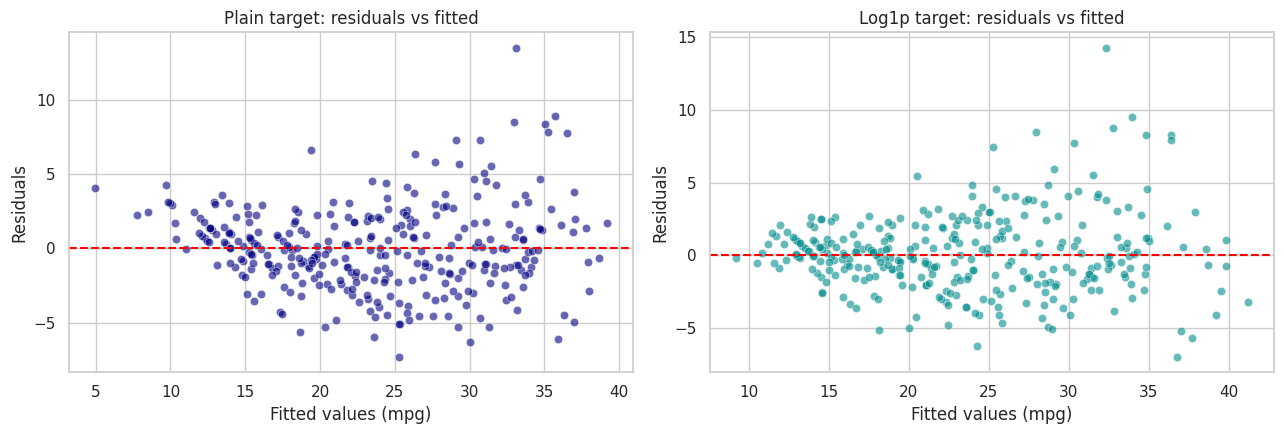

Saved: day7_residual_log_comparison.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(x=preds_standard, y=(y_train - preds_standard), ax=axes[0], color='navy', alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Plain target: residuals vs fitted')
axes[0].set_xlabel('Fitted values (mpg)')
axes[0].set_ylabel('Residuals')

sns.scatterplot(x=preds_log, y=(y_train - preds_log), ax=axes[1], color='darkcyan', alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Log1p target: residuals vs fitted')
axes[1].set_xlabel('Fitted values (mpg)')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.savefig('day7_residual_log_comparison.png')
plt.show()
print('Saved: day7_residual_log_comparison.png')


**What I see (fill in from the real plots):** On the left, do the dots fan out into a funnel as the fitted value grows? On the right, is the spread more even? If the right plot is clearly flatter, then the log target is doing real work. If the two look about the same, I shouldn't claim it helped just because the textbook says so.


## Step 3 — The fair race: 3 algorithms x raw vs engineered features Same folds, same seed, and the same imputing and scaling recipe for every contender, so the only thing that changes is the feature set and the model. I record the **train RMSE** next to the **CV RMSE** on purpose. A big gap between them is the classic sign of overfitting.


In [6]:
X_train_raw = train_raw.drop(columns=['mpg', 'name'])
num_features_raw = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
cat_features_raw = ['origin']

raw_preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features_raw),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_raw),
])

models = {
    'Linear Regression': LinearRegression(),
    'KNN Regressor (k=5)': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree (Default)': DecisionTreeRegressor(random_state=SEED),
}

cv_folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark_list = []

for space_label, x_data, preprocessor in [('Raw Features', X_train_raw, raw_preprocessor),
                                          ('Engineered Features', X_train_fe, fe_preprocessor)]:
    for m_name, algo in models.items():
        pipe = Pipeline([('pre', preprocessor), ('model', algo)])
        cv_scores = -cross_val_score(pipe, x_data, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error')
        pipe.fit(x_data, y_train)
        train_rmse = np.sqrt(mean_squared_error(y_train, pipe.predict(x_data)))

        benchmark_list.append({
            'Feature Space': space_label,
            'Model': m_name,
            'Train RMSE': round(train_rmse, 3),
            'CV RMSE Mean': round(cv_scores.mean(), 3),
            'CV RMSE Std': round(cv_scores.std(), 3),
        })

benchmark_df = pd.DataFrame(benchmark_list)
display(benchmark_df)


,Feature Space,Model,Train RMSE,CV RMSE Mean,CV RMSE Std
0,Raw Features,Linear Regression,3.370,3.478,0.224
1,Raw Features,KNN Regressor (k=5),2.531,3.163,0.177
2,Raw Features,Decision Tree (Default),0.000,3.856,0.392
3,Engineered Features,Linear Regression,2.875,3.211,0.286
4,Engineered Features,KNN Regressor (k=5),2.579,3.209,0.197
5,Engineered Features,Decision Tree (Default),0.000,3.840,0.091


**Questions to answer from the table:**
- Did the engineered features lower the CV RMSE for each model, or only for some of them?
- Which model has the biggest gap between Train RMSE and CV RMSE? My guess is the default decision tree, because a fully grown tree can memorise the training data. I'll check that against the real numbers.
- Is the improvement larger than the CV Std? If not, it may just be noise.


## Step 4 — Where does each model start to overfit? Two knobs control model flexibility:
- **Decision tree `max_depth`:** a shallow tree underfits and a deep tree memorises.
- **KNN `k`:** a small k follows every wiggle (high variance), and a big k smooths too much (high bias). I sweep both and plot train error against CV error. Where the CV line bottoms out is the sweet spot, and a train line that keeps falling while CV rises means overfitting.


In [7]:
# Sweep 1: decision tree depth
depth_range = range(1, 16)
dt_train_rmse = []
dt_cv_rmse = []

for d in depth_range:
    dt_pipe = Pipeline([('pre', fe_preprocessor), ('dt', DecisionTreeRegressor(max_depth=d, random_state=SEED))])
    cv_val = -cross_val_score(dt_pipe, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
    dt_pipe.fit(X_train_fe, y_train)
    dt_train_rmse.append(np.sqrt(mean_squared_error(y_train, dt_pipe.predict(X_train_fe))))
    dt_cv_rmse.append(cv_val)

# Sweep 2: KNN neighbours
k_range = range(1, 31)
knn_train_rmse = []
knn_cv_rmse = []

for k in k_range:
    knn_pipe = Pipeline([('pre', fe_preprocessor), ('knn', KNeighborsRegressor(n_neighbors=k))])
    cv_val = -cross_val_score(knn_pipe, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
    knn_pipe.fit(X_train_fe, y_train)
    knn_train_rmse.append(np.sqrt(mean_squared_error(y_train, knn_pipe.predict(X_train_fe))))
    knn_cv_rmse.append(cv_val)

best_depth = int(np.argmin(dt_cv_rmse)) + 1
best_k = int(np.argmin(knn_cv_rmse)) + 1
print(f'Best tree depth by CV: {best_depth} | Best k by CV: {best_k}')


Best tree depth by CV: 4 | Best k by CV: 9


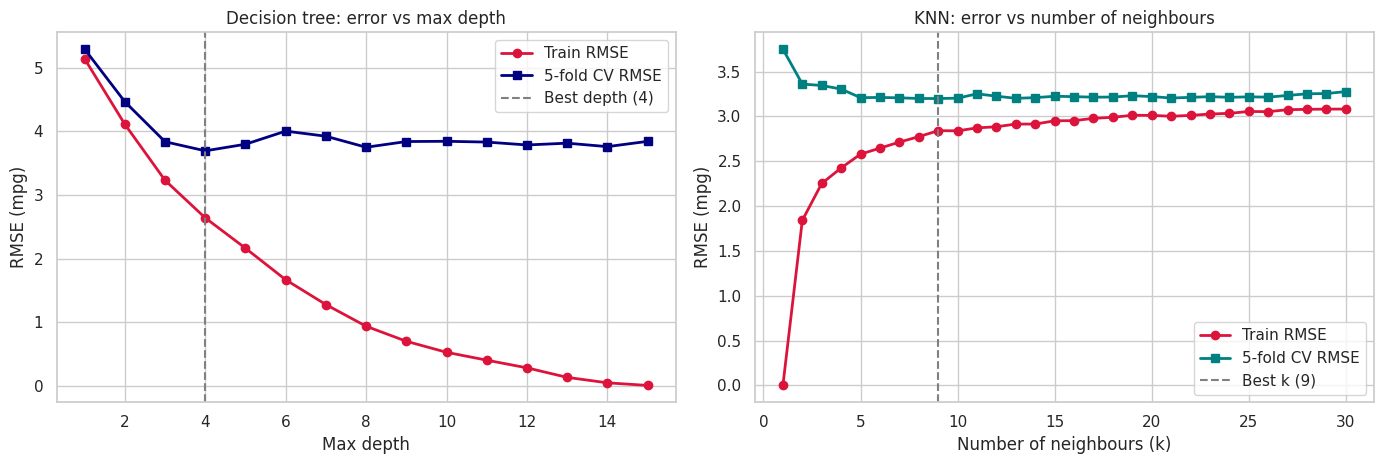

Saved: day7_bias_variance_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(depth_range, dt_train_rmse, marker='o', color='crimson', lw=2, label='Train RMSE')
axes[0].plot(depth_range, dt_cv_rmse, marker='s', color='navy', lw=2, label='5-fold CV RMSE')
axes[0].axvline(best_depth, color='gray', linestyle='--', label=f'Best depth ({best_depth})')
axes[0].set_title('Decision tree: error vs max depth')
axes[0].set_xlabel('Max depth')
axes[0].set_ylabel('RMSE (mpg)')
axes[0].legend()

axes[1].plot(k_range, knn_train_rmse, marker='o', color='crimson', lw=2, label='Train RMSE')
axes[1].plot(k_range, knn_cv_rmse, marker='s', color='teal', lw=2, label='5-fold CV RMSE')
axes[1].axvline(best_k, color='gray', linestyle='--', label=f'Best k ({best_k})')
axes[1].set_title('KNN: error vs number of neighbours')
axes[1].set_xlabel('Number of neighbours (k)')
axes[1].set_ylabel('RMSE (mpg)')
axes[1].legend()

plt.tight_layout()
plt.savefig('day7_bias_variance_curves.png')
plt.show()
print('Saved: day7_bias_variance_curves.png')


**Reading the curves (fill in from the real plots):**
- *Tree:* the train line should keep dropping toward zero as depth grows, while the CV line bottoms out and then flattens or rises. The gap between them is overfitting, and the best depth is where CV is lowest.
- *KNN:* at k=1 the train error is usually tiny, because each point is its own nearest neighbour, but CV is worse. As k grows, the two lines meet and then the model starts underfitting.
- One thing to keep in mind: choosing the best depth and k from CV is fine, but I must not go back and re-tune them by looking at the test set.


## Step 5 — The one and only look at the test set Everything above used training data only. Now I fit each model on the full training set, score it once on the held-out test cars, and put CV, train and test numbers into one table.


In [9]:
X_test_raw = test_raw.drop(columns=['mpg', 'name'])
y_test = test_raw['mpg']
X_test_fe = test_fe.drop(columns=['mpg'])

final_results = []
for space_label, x_tr, x_te, preproc in [('Raw Features', X_train_raw, X_test_raw, raw_preprocessor),
                                         ('Engineered Features', X_train_fe, X_test_fe, fe_preprocessor)]:
    for m_name, algo in models.items():
        pipe = Pipeline([('pre', preproc), ('model', algo)])
        cv_val = -cross_val_score(pipe, x_tr, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
        pipe.fit(x_tr, y_train)
        tr_eval = compute_regression_metrics(pipe, x_tr, y_train)
        te_eval = compute_regression_metrics(pipe, x_te, y_test)

        final_results.append({
            'Feature Space': space_label,
            'Algorithm': m_name,
            'CV RMSE': round(cv_val, 3),
            'Train RMSE': round(tr_eval['RMSE'], 3),
            'Test RMSE': round(te_eval['RMSE'], 3),
            'Test MAE': round(te_eval['MAE'], 3),
            'Test R2': round(te_eval['R2'], 3),
        })

final_df = pd.DataFrame(final_results)
display(final_df)


,Feature Space,Algorithm,CV RMSE,Train RMSE,Test RMSE,Test MAE,Test R2
0,Raw Features,Linear Regression,3.478,3.370,2.888,2.288,0.845
1,Raw Features,KNN Regressor (k=5),3.163,2.531,2.304,1.870,0.901
2,Raw Features,Decision Tree (Default),3.856,0.000,3.368,2.271,0.789
3,Engineered Features,Linear Regression,3.211,2.875,2.806,2.202,0.854
4,Engineered Features,KNN Regressor (k=5),3.209,2.579,2.430,1.858,0.890
5,Engineered Features,Decision Tree (Default),3.840,0.000,3.566,2.500,0.763


## Step 6 — Proving that KNN needs scaling KNN works by measuring distances. `weight` is in the thousands and `cylinders` is a single digit, so without scaling, weight would shout over everything else. Instead of just stating that, I test it: same model, same folds, with and without the `StandardScaler`.


In [10]:
unscaled_preproc = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_features_fe),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_fe),
])

knn_scaled = Pipeline([('pre', fe_preprocessor), ('knn', KNeighborsRegressor(n_neighbors=5))])
knn_unscaled = Pipeline([('pre', unscaled_preproc), ('knn', KNeighborsRegressor(n_neighbors=5))])

cv_scaled = -cross_val_score(knn_scaled, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
cv_unscaled = -cross_val_score(knn_unscaled, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()

print(f'Scaled KNN (k=5) CV RMSE:   {cv_scaled:.4f}')
print(f'Unscaled KNN (k=5) CV RMSE: {cv_unscaled:.4f}')
print(f'Error change from skipping scaling: {cv_unscaled - cv_scaled:+.4f} RMSE')


Scaled KNN (k=5) CV RMSE:   3.2093
Unscaled KNN (k=5) CV RMSE: 4.3381
Error change from skipping scaling: +1.1289 RMSE


## Step 7 — Stretch goals Three extra ideas, all judged by CV first:
- **Ridge** (L2 penalty) shrinks coefficients, which helps when features are close cousins like weight and displacement.
- **Lasso** (L1 penalty) can push some coefficients all the way to zero.
- **Ridge + polynomial interactions** lets features multiply with each other, with a stronger penalty to keep it from going wild.


In [11]:
stretch_results = []

# Ridge and Lasso
for r_name, r_model in [('Ridge (alpha=1.0)', Ridge(alpha=1.0)),
                        ('Lasso (alpha=0.05)', Lasso(alpha=0.05, random_state=SEED))]:
    r_pipe = Pipeline([('pre', fe_preprocessor), ('reg', r_model)])
    cv_val = -cross_val_score(r_pipe, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
    r_pipe.fit(X_train_fe, y_train)
    te_metrics = compute_regression_metrics(r_pipe, X_test_fe, y_test)
    stretch_results.append({
        'Model': r_name,
        'CV RMSE': round(cv_val, 3),
        'Test RMSE': round(te_metrics['RMSE'], 3),
        'Test R2': round(te_metrics['R2'], 3),
    })

# Polynomial interactions with a firmer Ridge penalty
poly_pipe = Pipeline([
    ('pre', fe_preprocessor),
    ('poly', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ('reg', Ridge(alpha=10.0)),
])
poly_cv = -cross_val_score(poly_pipe, X_train_fe, y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
poly_pipe.fit(X_train_fe, y_train)
poly_te = compute_regression_metrics(poly_pipe, X_test_fe, y_test)
stretch_results.append({
    'Model': 'Ridge + Polynomial (deg=2)',
    'CV RMSE': round(poly_cv, 3),
    'Test RMSE': round(poly_te['RMSE'], 3),
    'Test R2': round(poly_te['R2'], 3),
})

stretch_df = pd.DataFrame(stretch_results)
display(stretch_df)


,Model,CV RMSE,Test RMSE,Test R2
0,Ridge (alpha=1.0),3.206,2.772,0.857
1,Lasso (alpha=0.05),3.372,2.818,0.852
2,Ridge + Polynomial (deg=2),2.804,2.187,0.911


### Does the brand actually matter?
These are the brand coefficients from the plain linear model. Each bar says how many mpg a brand adds or subtracts **while engine specs are held constant**. That last part is important. It is not the same as "this brand is more efficient overall", because brands also differ in car size and weight, and those are handled by other features.


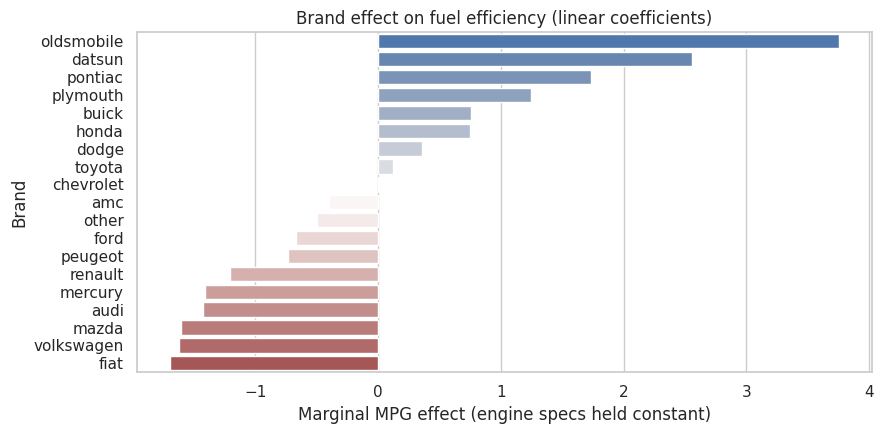

Saved: day7_brand_coefficients.png


In [12]:
lin_model = lin_standard.named_steps['reg']
feature_names = lin_standard.named_steps['pre'].get_feature_names_out()
brand_entries = [(n.replace('cat__brand_', ''), c)
                 for n, c in zip(feature_names, lin_model.coef_) if 'cat__brand_' in n]
brand_df = pd.DataFrame(brand_entries, columns=['Brand', 'Coefficient']).sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=brand_df, x='Coefficient', y='Brand', hue='Brand', palette='vlag', legend=False)
plt.title('Brand effect on fuel efficiency (linear coefficients)')
plt.xlabel('Marginal MPG effect (engine specs held constant)')
plt.tight_layout()
plt.savefig('day7_brand_coefficients.png')
plt.show()
print('Saved: day7_brand_coefficients.png')
